# 03 · The perceptron, from scratch

**Lecture:** *Perceptron* (06-08-2026) · **Notes:** `../notes/03_perceptron.md`

In this notebook you will:
1. Recompute the lecture's two worked examples in code (forward pass z = 1.4, and the weight update).
2. Build a `Perceptron` class in about 15 lines of NumPy and train it on the lecture's **Pass/Fail** example (hours of study x1, hours of practice x2).
3. Watch the decision boundary move as the perceptron learns.
4. Test the lecture's claims about the **learning rate**.
5. Prove the famous limitation: AND and OR are learnable, **XOR is not**. Then fix XOR with a tiny multi-layer network.

Everything runs in a few seconds. Change the numbers and re-run: that's the point.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=3, suppress=True)
rng = np.random.default_rng(0)

## 1 · The two building blocks: weighted sum and step activation

| Symbol | Meaning (lecture's notation) |
|---|---|
| x1, x2 | inputs: hours of study, hours of practice |
| w1, w2 | weights: how important each input is |
| b | bias: shifts the threshold |
| z | net input, **z = w1·x1 + w2·x2 + b** |
| f(z) | **step** activation: 1 if z ≥ 0, else 0 |
| ŷ (y_hat) | prediction: 1 = Pass, 0 = Fail |
| y | the true answer |
| η (eta) | learning rate |

In [2]:
def step(z):
    """Heaviside step: 1 if z >= 0 else 0 (works on numbers and arrays)."""
    return (np.asarray(z) >= 0).astype(int)

def forward(x, w, b):
    z = np.dot(w, x) + b          # weighted sum (net input)
    return z, step(z)             # (z, prediction)

# Lecture worked example 3.2: x1=2, x2=3, w1=0.5, w2=0.8, b=-2
z, y_hat = forward(np.array([2, 3]), np.array([0.5, 0.8]), -2)
print(f"z = 2*0.5 + 3*0.8 + (-2) = {z:.1f}  ->  f(z) = {y_hat}  ({'Pass' if y_hat else 'Fail'})")

z = 2*0.5 + 3*0.8 + (-2) = 1.4  ->  f(z) = 1  (Pass)


That matches the lecture: **z = 1.4, ŷ = 1 (Pass)**.

The step function plotted. Note the jump at z = 0: at exactly z = 0 the lecture's rule says "fire" (1).

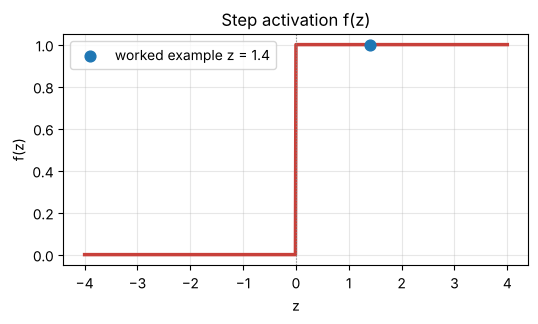

In [3]:
zs = np.linspace(-4, 4, 801)
plt.figure(figsize=(6, 3))
plt.plot(zs, step(zs), lw=2.5, color="#c8403a")
plt.axvline(0, color="grey", lw=0.8, ls=":")
plt.scatter([1.4], [1], s=60, zorder=3, label="worked example z = 1.4")
plt.title("Step activation f(z)"); plt.xlabel("z"); plt.ylabel("f(z)"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

## 2 · Learning: the perceptron update rule

Forward propagation only **predicts**. To **learn**, compare the prediction with the truth and nudge the weights:

  **wᵢ ← wᵢ + η · (y − ŷ) · xᵢ**   **b ← b + η · (y − ŷ)**

The error (y − ŷ) can only be −1, 0 or +1:
- **0**: the prediction was right, so nothing changes.
- **+1**: it said Fail but the answer was Pass (under-prediction), so the weights move **up** in proportion to each input.
- **−1**: it said Pass but the answer was Fail (over-prediction), so the weights move **down**.

Lecture worked example 5.2: x = (2, 3), w = (0.2, −0.4), b = −1.0, y = 1, ŷ = 0, η = 0.1.

In [4]:
def update(x, y, y_hat, w, b, eta):
    error = y - y_hat
    return w + eta * error * x, b + eta * error

w_new, b_new = update(np.array([2, 3]), 1, 0, np.array([0.2, -0.4]), -1.0, 0.1)
print("new weights:", w_new, " new bias:", round(b_new, 2))

# does the updated perceptron now get it right?
z_before, p_before = forward(np.array([2, 3]), np.array([0.2, -0.4]), -1.0)
z_after, p_after = forward(np.array([2, 3]), w_new, b_new)
print(f"before: z = {z_before:.2f} -> {p_before}   after one update: z = {z_after:.2f} -> {p_after}")

new weights: [ 0.4 -0.1]  new bias: -0.9
before: z = -1.80 -> 0   after one update: z = -0.40 -> 0


Matches the lecture: **w1 = 0.4, w2 = −0.1, b = −0.9**. Notice two things the lecture doesn't spell out:
- One update moved z from −1.8 to −0.4. That is **closer** to the threshold, but the prediction is **still wrong** (0). Learning takes several passes over the data.
- Each weight moved **in proportion to its input** (x2 = 3 moved w2 more than x1 = 2 moved w1). Inputs that were "louder" get more of the blame.

## 3 · A `Perceptron` class, trained on Pass/Fail data

Made-up but realistic data: 60 students. A student passes if 0.6·study + 0.4·practice is above 5, a hidden rule the perceptron has to discover. Borderline students (score within 0.4 of 5) are left out, so there is a clear gap between Pass and Fail.

In [5]:
class Perceptron:
    def __init__(self, n_inputs, eta=0.1, w_init=None):
        self.w = np.zeros(n_inputs) if w_init is None else np.array(w_init, float)
        self.b = 0.0
        self.eta = eta
        self.history = []                      # (w, b, mistakes) after every epoch

    def predict(self, X):
        return step(X @ self.w + self.b)

    def fit(self, X, y, epochs=20, verbose=False):
        for epoch in range(epochs):
            mistakes = 0
            for xi, yi in zip(X, y):           # one example at a time (online learning)
                y_hat = step(xi @ self.w + self.b)
                error = yi - y_hat
                self.w += self.eta * error * xi
                self.b += self.eta * error
                mistakes += int(error != 0)
            self.history.append((self.w.copy(), self.b, mistakes))
            if verbose and (epoch < 5 or mistakes == 0 or (epoch + 1) % 10 == 0):
                print(f"epoch {epoch + 1:2d}: mistakes = {mistakes:2d}   w = {self.w}  b = {self.b:.2f}")
            if mistakes == 0:                  # converged: every training example correct
                break
        return self

# the data
study = rng.uniform(0, 10, 200)
practice = rng.uniform(0, 10, 200)
score = 0.6 * study + 0.4 * practice
keep = np.abs(score - 5) > 0.4            # drop borderline students so a clear gap exists
study, practice, score = study[keep][:60], practice[keep][:60], score[keep][:60]
n = len(study)
y = (score > 5).astype(int)
X = np.column_stack([study, practice])
print("students:", n, "  passed:", y.sum(), "  failed:", n - y.sum())

p = Perceptron(2, eta=0.1).fit(X, y, epochs=500, verbose=True)
print("training accuracy:", (p.predict(X) == y).mean())

students: 60   passed: 29   failed: 31
epoch  1: mistakes = 31   w = [ 0.46  -0.832]  b = -1.10
epoch  2: mistakes = 21   w = [ 0.777 -0.61 ]  b = -1.60
epoch  3: mistakes = 22   w = [ 0.586 -0.275]  b = -2.20
epoch  4: mistakes = 22   w = [ 0.836 -0.388]  b = -2.80
epoch  5: mistakes = 21   w = [ 0.846 -0.088]  b = -3.30
epoch 10: mistakes = 16   w = [ 0.891 -0.048]  b = -5.50
epoch 19: mistakes =  0   w = [0.835 0.714]  b = -7.60
training accuracy: 1.0


The number of mistakes per epoch shrinks to **0**: the perceptron found a line that separates every Pass from every Fail. The **perceptron convergence theorem** guarantees this happens in a finite number of steps **if** such a line exists (the data is linearly separable).

### Watching the decision boundary move
The boundary is the line where z = 0: w1·x1 + w2·x2 + b = 0, i.e. x2 = −(w1·x1 + b)/w2.

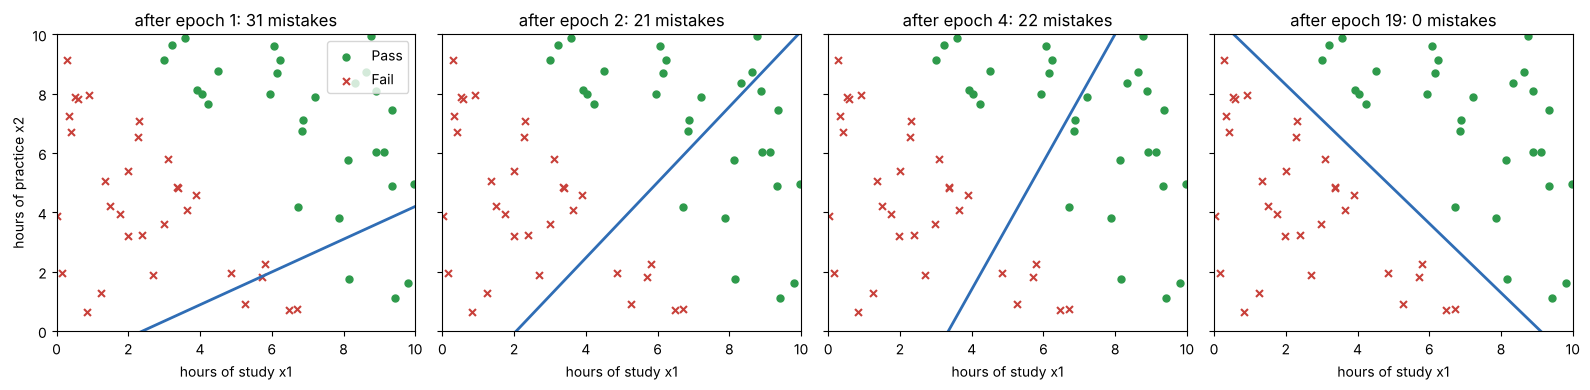

In [6]:
def draw_boundary(ax, w, b, **kw):
    xs = np.array([0, 10])
    if abs(w[1]) > 1e-9:
        ax.plot(xs, -(w[0] * xs + b) / w[1], **kw)
    elif abs(w[0]) > 1e-9:
        ax.axvline(-b / w[0], **kw)

epochs_to_show = [0, 1, 3, len(p.history) - 1]
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, e in zip(axes, epochs_to_show):
    w_e, b_e, m_e = p.history[e]
    ax.scatter(*X[y == 1].T, c="#2e9a4b", label="Pass", s=25)
    ax.scatter(*X[y == 0].T, c="#c8403a", label="Fail", s=25, marker="x")
    draw_boundary(ax, w_e, b_e, color="#2f6db5", lw=2)
    ax.set_xlim(0, 10); ax.set_ylim(0, 10)
    ax.set_title(f"after epoch {e + 1}: {m_e} mistakes"); ax.set_xlabel("hours of study x1")
axes[0].set_ylabel("hours of practice x2"); axes[0].legend(loc="upper right")
plt.tight_layout(); plt.show()

## 4 · Does the learning rate matter? (testing the lecture's claims)

The lecture says: η too small → slow; η too large → overshoot/diverge. That is true for **gradient descent** on a smooth loss (section 5 shows it). For the classic perceptron there is a surprise worth knowing:

In [7]:
for eta in [0.001, 0.01, 0.1, 1.0, 10.0]:
    pz = Perceptron(2, eta=eta).fit(X, y, epochs=200)          # weights start at zero
    pr = Perceptron(2, eta=eta, w_init=[-1.0, 1.0]).fit(X, y, epochs=200)   # weights start elsewhere
    print(f"eta = {eta:>6}:  start at zero -> {len(pz.history):3d} epochs  |  start at (-1, 1) -> {len(pr.history):3d} epochs")

eta =  0.001:  start at zero ->  19 epochs  |  start at (-1, 1) ->  19 epochs
eta =   0.01:  start at zero ->  19 epochs  |  start at (-1, 1) ->  13 epochs
eta =    0.1:  start at zero ->  19 epochs  |  start at (-1, 1) ->  13 epochs
eta =    1.0:  start at zero ->  19 epochs  |  start at (-1, 1) ->  18 epochs
eta =   10.0:  start at zero ->  19 epochs  |  start at (-1, 1) ->   3 epochs


**What the numbers show:** when the weights start at **zero**, every η takes **exactly the same number of epochs**. The step function only looks at the **sign** of z, and multiplying all the weights and the bias by η doesn't change any sign. So η just rescales the whole solution. When the weights start somewhere else, η does matter, because it sets how big the corrections are compared with the starting weights.

The lecture's learning-rate trade-off is really about **gradient descent on a smooth loss**, which modern networks use. Here it is:

## 5 · Gradient descent: walking downhill on a loss curve

A loss curve L(w) = (w − 1)² + 0.5. Its slope is 2(w − 1). Each step: **w ← w − η · slope**.

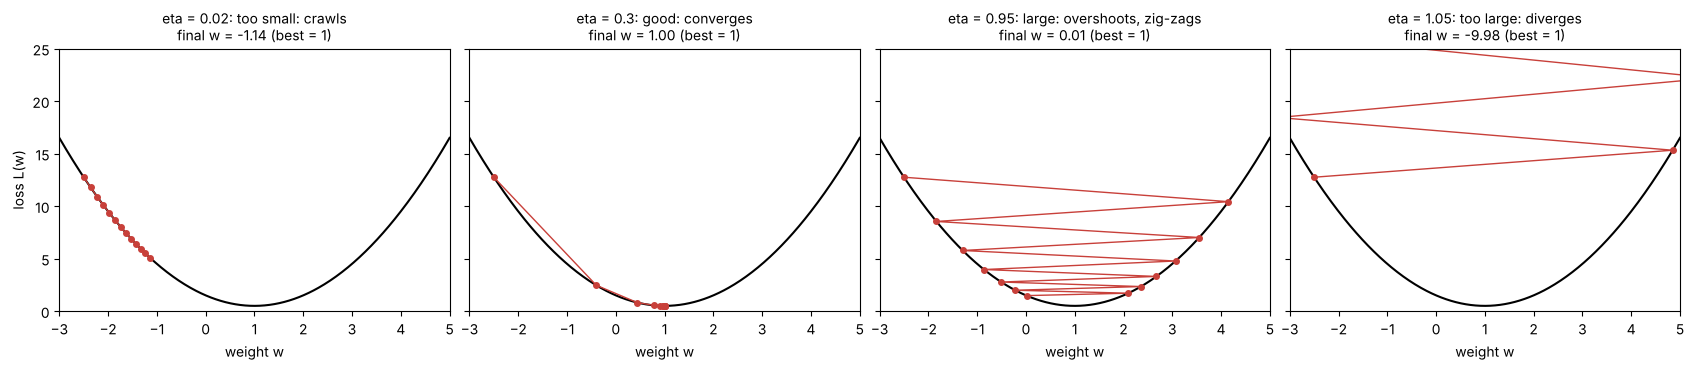

In [8]:
L = lambda w: (w - 1) ** 2 + 0.5
dL = lambda w: 2 * (w - 1)

def descend(w0, eta, steps=12):
    ws = [w0]
    for _ in range(steps):
        ws.append(ws[-1] - eta * dL(ws[-1]))
    return np.array(ws)

ws_grid = np.linspace(-3, 5, 400)
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), sharey=True)
for ax, (eta, title) in zip(axes, [(0.02, "too small: crawls"), (0.3, "good: converges"),
                                    (0.95, "large: overshoots, zig-zags"), (1.05, "too large: diverges")]):
    path = descend(-2.5, eta)
    ax.plot(ws_grid, L(ws_grid), color="black", lw=1.5)
    ax.plot(path, L(path), "o-", color="#c8403a", ms=4, lw=1)
    ax.set_title(f"eta = {eta}: {title}\nfinal w = {path[-1]:.2f} (best = 1)", fontsize=10)
    ax.set_ylim(0, 25); ax.set_xlim(-3, 5); ax.set_xlabel("weight w")
axes[0].set_ylabel("loss L(w)")
plt.tight_layout(); plt.show()

This confirms the lecture's trade-off: tiny steps crawl, good steps arrive quickly, large steps zig-zag across the valley, and **too-large steps make the loss grow** (diverge).

> **Local vs global minimum:** this loss has only one valley, so any converging η finds the global minimum. Real neural-network losses have many valleys and flat regions, and there the step size (and luck) affect where you end up.

## 6 · Linear separability: AND ✓, OR ✓, XOR ✗

AND: weights [0.2 0.1], bias -0.2, accuracy 100%, converged = True
OR: weights [0.1 0.1], bias -0.1, accuracy 100%, converged = True
XOR: weights [-0.1  0. ], bias 0.0, accuracy 50%, converged = False


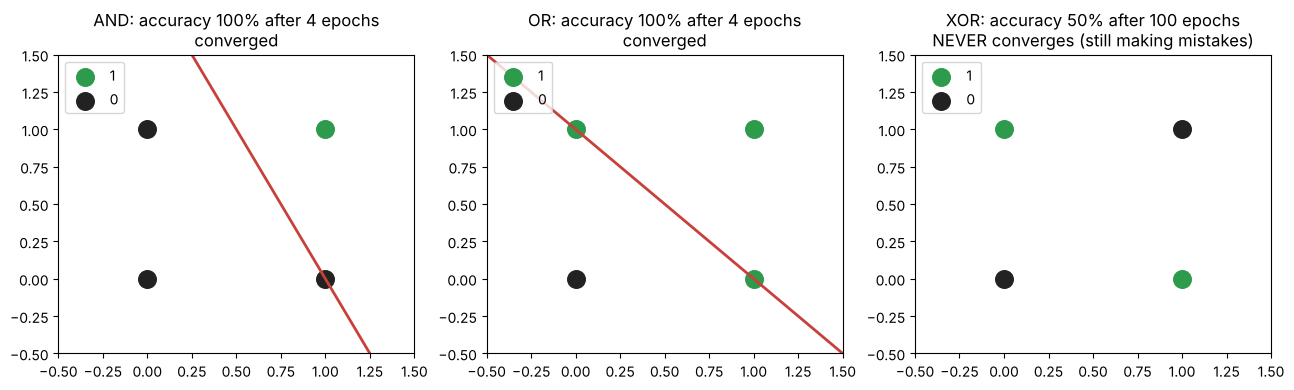

In [9]:
X_gate = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
gates = {"AND": np.array([0, 0, 0, 1]), "OR": np.array([0, 1, 1, 1]), "XOR": np.array([0, 1, 1, 0])}

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, yg) in zip(axes, gates.items()):
    pg = Perceptron(2, eta=0.1).fit(X_gate, yg, epochs=100)
    acc = (pg.predict(X_gate) == yg).mean()
    converged = pg.history[-1][2] == 0
    ax.scatter(*X_gate[yg == 1].T, s=160, c="#2e9a4b", label="1")
    ax.scatter(*X_gate[yg == 0].T, s=160, c="#222", label="0")
    xs = np.array([-0.5, 1.5])
    w_g, b_g = pg.w, pg.b
    if abs(w_g[1]) > 1e-9:
        ax.plot(xs, -(w_g[0] * xs + b_g) / w_g[1], color="#c8403a", lw=2)
    ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5)
    ax.set_title(f"{name}: accuracy {acc:.0%} after {len(pg.history)} epochs\n"
                 f"{'converged' if converged else 'NEVER converges (still making mistakes)'}")
    ax.legend(loc="upper left")
    print(f"{name}: weights {pg.w}, bias {pg.b:.1f}, accuracy {acc:.0%}, converged = {converged}")
plt.tight_layout(); plt.show()

### A closer look: the AND line passes right through a point

Look at the AND panel: the learned line goes **exactly through (1, 0)**. Let's print z for every input:

In [10]:
p_and = Perceptron(2, eta=0.1).fit(X_gate, gates["AND"], epochs=100)
for x in X_gate:
    z = x @ p_and.w + p_and.b
    print(f"x = {x}: z = {z:+.20f} -> prediction {step(z)}")

x = [0 0]: z = -0.20000000000000003886 -> prediction 0
x = [0 1]: z = -0.10000000000000003331 -> prediction 0
x = [1 0]: z = -0.00000000000000002776 -> prediction 0
x = [1 1]: z = +0.10000000000000000555 -> prediction 1


For (1, 0), z is a tiny number from floating-point rounding, not a real margin. Mathematically 0.2 + (−0.2) = 0, which the step function would call **1**, a wrong answer for AND. The run is correct only because of a rounding hair.

Two lessons:
- The perceptron **stops as soon as it makes no mistakes**, however close a point sits to the line. It doesn't look for a *safe* boundary.
- Algorithms that maximise the **margin** (the gap between the line and the nearest points), like the **Support Vector Machine**, were designed to fix exactly this. A boundary with a wide margin generalises better to new, slightly different inputs.

In [11]:
# Can ANY single line do better on XOR? Try 200,000 random lines and keep the best.
W = rng.normal(size=(200_000, 2)); B = rng.normal(size=200_000)
preds = step(X_gate @ W.T + B)                          # shape (4, 200000)
best = (preds == gates["XOR"][:, None]).mean(axis=0).max()
print(f"best accuracy of any of 200,000 random lines on XOR: {best:.0%}")

best accuracy of any of 200,000 random lines on XOR: 75%


**No straight line gets more than 3 of the 4 XOR points right (75%).** This is the limitation Minsky and Papert published in 1969, and it helped start the first "AI winter".

## 7 · The fix: add a hidden layer (a multi-layer perceptron)

XOR = (x1 OR x2) AND NOT (x1 AND x2). Two perceptrons in a hidden layer compute OR and NAND, and one output perceptron ANDs them. **Hand-set weights:**

In [12]:
def mlp_xor(x):
    h_or   = step(x @ np.array([1, 1]) - 0.5)        # OR
    h_nand = step(x @ np.array([-1, -1]) + 1.5)      # NAND = NOT(AND)
    return step(h_or + h_nand - 1.5)                 # AND of the two hidden neurons

for x in X_gate:
    print(x, "->", mlp_xor(x))

[0 0] -> 0
[0 1] -> 1
[1 0] -> 1
[1 1] -> 0


Now let a network **learn** XOR by itself. The step function's slope is zero everywhere, so gradient descent can't train it. We swap in a smooth activation (sigmoid, see notebook 04) and use **backpropagation**, the 1986 algorithm that ended the AI winter.

final loss: 0.003
outputs: [0.003 0.997 0.997 0.003] -> rounded: [0, 1, 1, 0]


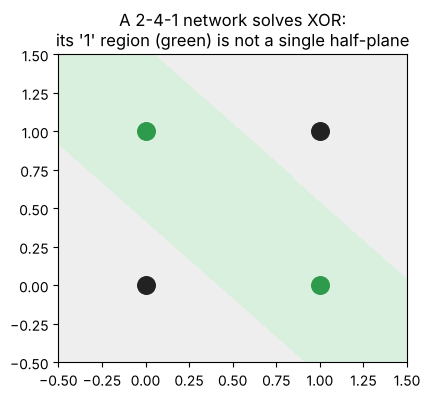

In [13]:
import torch, torch.nn as nn
torch.manual_seed(0)
Xt = torch.tensor(X_gate, dtype=torch.float32); yt = torch.tensor(gates["XOR"], dtype=torch.float32).unsqueeze(1)
net = nn.Sequential(nn.Linear(2, 4), nn.Sigmoid(), nn.Linear(4, 1), nn.Sigmoid())   # 2 -> 4 hidden -> 1
opt = torch.optim.SGD(net.parameters(), lr=1.0)
for epoch in range(3000):
    loss = nn.functional.binary_cross_entropy(net(Xt), yt)
    opt.zero_grad(); loss.backward(); opt.step()
print("final loss:", round(loss.item(), 4))
print("outputs:", net(Xt).detach().squeeze().numpy().round(3), "-> rounded:", (net(Xt) > 0.5).int().squeeze().tolist())

# the curved decision region it learned
g = np.linspace(-0.5, 1.5, 200); GX, GY = np.meshgrid(g, g)
grid = torch.tensor(np.column_stack([GX.ravel(), GY.ravel()]), dtype=torch.float32)
Z = net(grid).detach().numpy().reshape(GX.shape)
plt.figure(figsize=(4.5, 4))
plt.contourf(GX, GY, Z > 0.5, levels=1, colors=["#eeeeee", "#d9f0df"])
plt.scatter(*X_gate[gates["XOR"] == 1].T, s=160, c="#2e9a4b"); plt.scatter(*X_gate[gates["XOR"] == 0].T, s=160, c="#222")
plt.title("A 2-4-1 network solves XOR:\nits '1' region (green) is not a single half-plane"); plt.show()

The hidden layer lets the network **bend** its decision region, which a single line can't do. That is the whole reason for "deep" networks.

## ✅ Check yourself
1. Compute by hand: x = (1, 4), w = (0.5, −0.5), b = 1. What are z and ŷ? *(z = 0.5 − 2 + 1 = −0.5 → ŷ = 0)*
2. The perceptron predicted 1 but the answer is 0, with η = 0.5 and x = (2, 1). How does each weight change? *(error = −1 → w1 −1.0, w2 −0.5, b −0.5)*
3. Why does the perceptron stop updating once it gets everything right? *(error = 0 for every example, so the update is 0)*
4. Why can't a single perceptron learn XOR, and what fixes it? *(one straight line can't separate XOR's diagonal pattern; a hidden layer, i.e. an MLP, bends the boundary)*
5. Why can't you train a step-function network with gradient descent? *(the step's slope is 0 everywhere except the jump, so there's no gradient signal; use smooth activations like sigmoid or ReLU)*

**Try this:** add noise so a few Pass/Fail labels are wrong (flip 3 labels) and re-run section 3. Does the perceptron still converge? *(No. The data is no longer linearly separable, so it keeps making mistakes, just like XOR.)*